In [ ]:
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("nikhilmittal/flight-fare-prediction-mh")

# print("Path to dataset files:", path)

In [104]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import openpyxl

sns.set()

In [105]:
train_df = pd.read_excel("../../../../datasets/flight_fare/Data_Train.xlsx", engine="openpyxl")
test_df = pd.read_excel("../../../../datasets/flight_fare/Test_set.xlsx", engine="openpyxl")

In [106]:
train_df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [107]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10683 non-null  str  
 1   Date_of_Journey  10683 non-null  str  
 2   Source           10683 non-null  str  
 3   Destination      10683 non-null  str  
 4   Route            10682 non-null  str  
 5   Dep_Time         10683 non-null  str  
 6   Arrival_Time     10683 non-null  str  
 7   Duration         10683 non-null  str  
 8   Total_Stops      10682 non-null  str  
 9   Additional_Info  10683 non-null  str  
 10  Price            10683 non-null  int64
dtypes: int64(1), str(10)
memory usage: 1.8 MB


In [108]:
train_df["Duration"].value_counts()

Duration
2h 50m     550
1h 30m     386
2h 55m     337
2h 45m     337
2h 35m     329
          ... 
29h 30m      1
32h 20m      1
40h 20m      1
13h 35m      1
47h 40m      1
Name: count, Length: 368, dtype: int64

In [109]:
train_df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [110]:
train_df.dropna(inplace=True)
train_df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64

In [111]:
train_df["Journey_day"] = pd.to_datetime(train_df.Date_of_Journey, format="%d/%m/%Y").dt.day

In [112]:
train_df["Journey_month"] = pd.to_datetime(train_df.Date_of_Journey, format="%d/%m/%Y").dt.month
train_df["Journey_year"] = pd.to_datetime(train_df.Date_of_Journey, format="%d/%m/%Y").dt.year
train_df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_day,Journey_month,Journey_year
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,2019
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5,2019
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,9,6,2019
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5,2019
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3,2019


In [113]:
train_df.drop(["Date_of_Journey"], axis=1, inplace=True)

In [114]:
train_df["Departure_hour"] = pd.to_datetime(train_df["Dep_Time"]).dt.hour
train_df.head()

C:\Users\Himanshu\AppData\Local\Temp\ipykernel_15928\3085529473.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  train_df["Departure_hour"] = pd.to_datetime(train_df["Dep_Time"]).dt.hour


,Airline,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_day,Journey_month,Journey_year,Departure_hour
0,IndiGo,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,2019,22
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,1,5,2019,5
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,9,6,2019,9
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218,12,5,2019,18
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302,1,3,2019,16


In [115]:
train_df["Departure_minute"] = pd.to_datetime(train_df["Dep_Time"]).dt.minute
train_df.drop(["Dep_Time"], axis=1, inplace=True)
train_df.head()

C:\Users\Himanshu\AppData\Local\Temp\ipykernel_15928\3620750928.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  train_df["Departure_minute"] = pd.to_datetime(train_df["Dep_Time"]).dt.minute


,Airline,Source,Destination,Route,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_day,Journey_month,Journey_year,Departure_hour,Departure_minute
0,IndiGo,Banglore,New Delhi,BLR → DEL,01:10 22 Mar,2h 50m,non-stop,No info,3897,24,3,2019,22,20
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,13:15,7h 25m,2 stops,No info,7662,1,5,2019,5,50
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,04:25 10 Jun,19h,2 stops,No info,13882,9,6,2019,9,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,23:30,5h 25m,1 stop,No info,6218,12,5,2019,18,5
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,21:35,4h 45m,1 stop,No info,13302,1,3,2019,16,50


In [116]:
train_df["Arrival_hour"] = pd.to_datetime(train_df["Arrival_Time"]).dt.hour
train_df["Arrival_minute"] = pd.to_datetime(train_df["Arrival_Time"]).dt.minute
train_df.drop(["Arrival_Time"], axis=1, inplace=True)
train_df.head()

C:\Users\Himanshu\AppData\Local\Temp\ipykernel_15928\1807445690.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  train_df["Arrival_hour"] = pd.to_datetime(train_df["Arrival_Time"]).dt.hour
C:\Users\Himanshu\AppData\Local\Temp\ipykernel_15928\1807445690.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  train_df["Arrival_minute"] = pd.to_datetime(train_df["Arrival_Time"]).dt.minute


,Airline,Source,Destination,Route,Duration,Total_Stops,Additional_Info,Price,Journey_day,Journey_month,Journey_year,Departure_hour,Departure_minute,Arrival_hour,Arrival_minute
0,IndiGo,Banglore,New Delhi,BLR → DEL,2h 50m,non-stop,No info,3897,24,3,2019,22,20,1,10
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,7h 25m,2 stops,No info,7662,1,5,2019,5,50,13,15
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,19h,2 stops,No info,13882,9,6,2019,9,25,4,25
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,5h 25m,1 stop,No info,6218,12,5,2019,18,5,23,30
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,4h 45m,1 stop,No info,13302,1,3,2019,16,50,21,35


In [117]:
duration = list(train_df["Duration"])

for i in range(len(duration)):
    if len(duration[i].split()) != 2:
        if "h" in duration[i]:
            duration[i] = duration[i].strip() + " 0m"
            
        else:
            duration[i] = "0h " + duration[i]



In [118]:
duration_hours = []
duration_minutes = []
for i in range(len(duration)):
    duration_hours.append(int(duration[i].split(sep="h")[0]))
    duration_minutes.append(int(duration[i].split(sep="m")[0].split()[-1]))

In [119]:
train_df["Duration_hours"] = duration_hours
train_df["Duration_minutes"] = duration_minutes

In [120]:
train_df.drop(["Duration"], axis=1, inplace=True)

In [121]:
train_df.head()

,Airline,Source,Destination,Route,Total_Stops,Additional_Info,Price,Journey_day,Journey_month,Journey_year,Departure_hour,Departure_minute,Arrival_hour,Arrival_minute,Duration_hours,Duration_minutes
0,IndiGo,Banglore,New Delhi,BLR → DEL,non-stop,No info,3897,24,3,2019,22,20,1,10,2,50
1,Air India,Kolkata,Banglore,CCU → IXR → BBI → BLR,2 stops,No info,7662,1,5,2019,5,50,13,15,7,25
2,Jet Airways,Delhi,Cochin,DEL → LKO → BOM → COK,2 stops,No info,13882,9,6,2019,9,25,4,25,19,0
3,IndiGo,Kolkata,Banglore,CCU → NAG → BLR,1 stop,No info,6218,12,5,2019,18,5,23,30,5,25
4,IndiGo,Banglore,New Delhi,BLR → NAG → DEL,1 stop,No info,13302,1,3,2019,16,50,21,35,4,45


In [122]:
train_df["Airline"].value_counts()

Airline
Jet Airways                          3849
IndiGo                               2053
Air India                            1751
Multiple carriers                    1196
SpiceJet                              818
Vistara                               479
Air Asia                              319
GoAir                                 194
Multiple carriers Premium economy      13
Jet Airways Business                    6
Vistara Premium economy                 3
Trujet                                  1
Name: count, dtype: int64

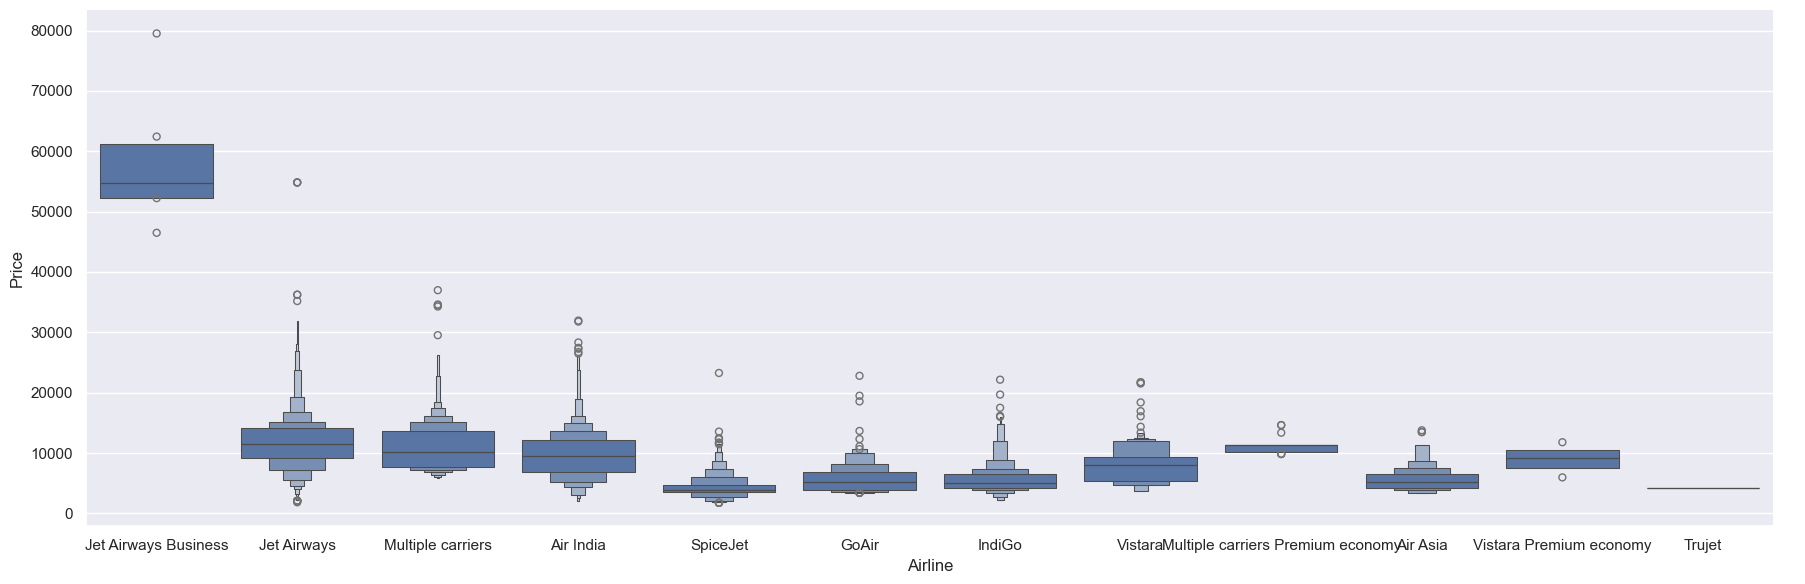

In [123]:
sns.catplot(
    y="Price",
    x ='Airline',
    data=train_df.sort_values("Price", ascending=False),
    kind="boxen",
    height=6,
    aspect=3
    )
plt.show()

In [124]:
Airline = train_df[["Airline"]]
Airline = pd.get_dummies(Airline, drop_first=True)
Airline.head()

,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,Airline_Vistara,Airline_Vistara Premium economy
0,False,False,True,False,False,False,False,False,False,False,False
1,True,False,False,False,False,False,False,False,False,False,False
2,False,False,False,True,False,False,False,False,False,False,False
3,False,False,True,False,False,False,False,False,False,False,False
4,False,False,True,False,False,False,False,False,False,False,False


In [125]:
train_df["Source"].value_counts()

Source
Delhi       4536
Kolkata     2871
Banglore    2197
Mumbai       697
Chennai      381
Name: count, dtype: int64

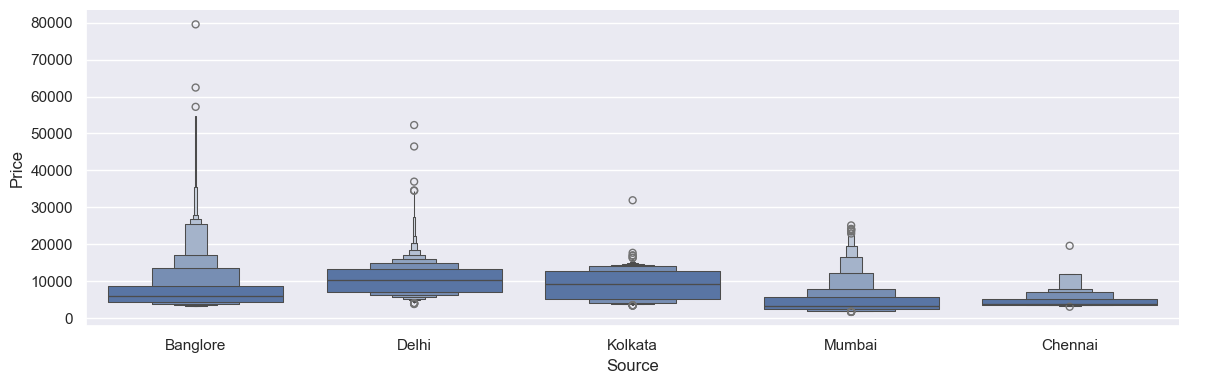

In [126]:
sns.catplot(
    y="Price",
    x="Source",
    data=train_df.sort_values("Price",ascending=False),
    kind="boxen",
    height=4,
    aspect=3
)
plt.show()

In [127]:
Source=train_df[["Source"]]
Source=pd.get_dummies(Source, drop_first=True)
Source.head()

,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai
0,False,False,False,False
1,False,False,True,False
2,False,True,False,False
3,False,False,True,False
4,False,False,False,False


In [128]:
train_df["Destination"].value_counts()

Destination
Cochin       4536
Banglore     2871
Delhi        1265
New Delhi     932
Hyderabad     697
Kolkata       381
Name: count, dtype: int64

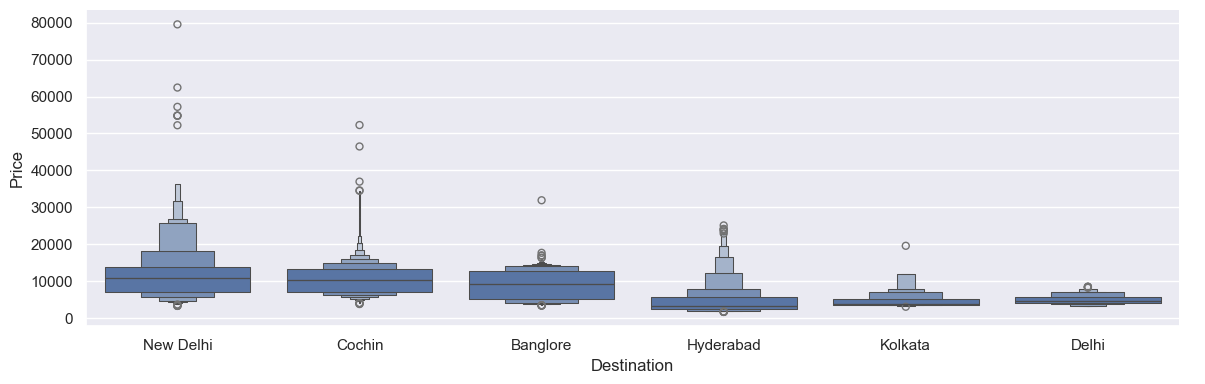

In [129]:
sns.catplot(
    y="Price",
    x="Destination",
    data=train_df.sort_values("Price",ascending=False),
    kind="boxen",
    height=4,
    aspect=3
)
plt.show()

In [130]:
Destination = train_df[["Destination"]]
Destination = pd.get_dummies(Destination, drop_first=True)
Destination.head()

,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,False,False,False,False,True
1,False,False,False,False,False
2,True,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,True


In [131]:
train_df["Route"]

0                    BLR → DEL
1        CCU → IXR → BBI → BLR
2        DEL → LKO → BOM → COK
3              CCU → NAG → BLR
4              BLR → NAG → DEL
                 ...          
10678                CCU → BLR
10679                CCU → BLR
10680                BLR → DEL
10681                BLR → DEL
10682    DEL → GOI → BOM → COK
Name: Route, Length: 10682, dtype: str

In [132]:
train_df.drop(["Route", "Additional_Info"], axis=1,inplace=True)

In [133]:
train_df["Total_Stops"].value_counts()

Total_Stops
1 stop      5625
non-stop    3491
2 stops     1520
3 stops       45
4 stops        1
Name: count, dtype: int64

In [134]:
train_df.replace({
    "non-stop":0,
    "1 stop": 1,
    "2 stops":2,
    "3 stops":3,
    "4 stops":4
}, inplace=True)

,Airline,Source,Destination,Total_Stops,Price,Journey_day,Journey_month,Journey_year,Departure_hour,Departure_minute,Arrival_hour,Arrival_minute,Duration_hours,Duration_minutes
0,IndiGo,Banglore,New Delhi,0,3897,24,3,2019,22,20,1,10,2,50
1,Air India,Kolkata,Banglore,2,7662,1,5,2019,5,50,13,15,7,25
2,Jet Airways,Delhi,Cochin,2,13882,9,6,2019,9,25,4,25,19,0
3,IndiGo,Kolkata,Banglore,1,6218,12,5,2019,18,5,23,30,5,25
4,IndiGo,Banglore,New Delhi,1,13302,1,3,2019,16,50,21,35,4,45
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,Kolkata,Banglore,0,4107,9,4,2019,19,55,22,25,2,30
10679,Air India,Kolkata,Banglore,0,4145,27,4,2019,20,45,23,20,2,35
10680,Jet Airways,Banglore,Delhi,0,7229,27,4,2019,8,20,11,20,3,0
10681,Vistara,Banglore,New Delhi,0,12648,1,3,2019,11,30,14,10,2,40


In [135]:
train_df["Total_Stops"].value_counts()

Total_Stops
1    5625
0    3491
2    1520
3      45
4       1
Name: count, dtype: int64

In [136]:
train_df = pd.concat([train_df, Airline, Source, Destination], axis=1)

In [137]:
train_df

,Airline,Source,Destination,Total_Stops,Price,Journey_day,Journey_month,Journey_year,Departure_hour,Departure_minute,...,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,IndiGo,Banglore,New Delhi,0,3897,24,3,2019,22,20,...,False,False,False,False,False,False,False,False,False,True
1,Air India,Kolkata,Banglore,2,7662,1,5,2019,5,50,...,False,False,False,True,False,False,False,False,False,False
2,Jet Airways,Delhi,Cochin,2,13882,9,6,2019,9,25,...,False,False,True,False,False,True,False,False,False,False
3,IndiGo,Kolkata,Banglore,1,6218,12,5,2019,18,5,...,False,False,False,True,False,False,False,False,False,False
4,IndiGo,Banglore,New Delhi,1,13302,1,3,2019,16,50,...,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,Kolkata,Banglore,0,4107,9,4,2019,19,55,...,False,False,False,True,False,False,False,False,False,False
10679,Air India,Kolkata,Banglore,0,4145,27,4,2019,20,45,...,False,False,False,True,False,False,False,False,False,False
10680,Jet Airways,Banglore,Delhi,0,7229,27,4,2019,8,20,...,False,False,False,False,False,False,True,False,False,False
10681,Vistara,Banglore,New Delhi,0,12648,1,3,2019,11,30,...,False,False,False,False,False,False,False,False,False,True


In [138]:
train_df.drop(["Airline", "Source", "Destination"], axis=1, inplace=True)
train_df.head()

,Total_Stops,Price,Journey_day,Journey_month,Journey_year,Departure_hour,Departure_minute,Arrival_hour,Arrival_minute,Duration_hours,...,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0,3897,24,3,2019,22,20,1,10,2,...,False,False,False,False,False,False,False,False,False,True
1,2,7662,1,5,2019,5,50,13,15,7,...,False,False,False,True,False,False,False,False,False,False
2,2,13882,9,6,2019,9,25,4,25,19,...,False,False,True,False,False,True,False,False,False,False
3,1,6218,12,5,2019,18,5,23,30,5,...,False,False,False,True,False,False,False,False,False,False
4,1,13302,1,3,2019,16,50,21,35,4,...,False,False,False,False,False,False,False,False,False,True


In [139]:
train_df.info()

<class 'pandas.DataFrame'>
Index: 10682 entries, 0 to 10682
Data columns (total 31 columns):
 #   Column                                     Non-Null Count  Dtype 
---  ------                                     --------------  ----- 
 0   Total_Stops                                10682 non-null  object
 1   Price                                      10682 non-null  int64 
 2   Journey_day                                10682 non-null  int32 
 3   Journey_month                              10682 non-null  int32 
 4   Journey_year                               10682 non-null  int32 
 5   Departure_hour                             10682 non-null  int32 
 6   Departure_minute                           10682 non-null  int32 
 7   Arrival_hour                               10682 non-null  int32 
 8   Arrival_minute                             10682 non-null  int32 
 9   Duration_hours                             10682 non-null  int64 
 10  Duration_minutes                           10682 n

In [140]:
test_df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info
0,Jet Airways,6/06/2019,Delhi,Cochin,DEL → BOM → COK,17:30,04:25 07 Jun,10h 55m,1 stop,No info
1,IndiGo,12/05/2019,Kolkata,Banglore,CCU → MAA → BLR,06:20,10:20,4h,1 stop,No info
2,Jet Airways,21/05/2019,Delhi,Cochin,DEL → BOM → COK,19:15,19:00 22 May,23h 45m,1 stop,In-flight meal not included
3,Multiple carriers,21/05/2019,Delhi,Cochin,DEL → BOM → COK,08:00,21:00,13h,1 stop,No info
4,Air Asia,24/06/2019,Banglore,Delhi,BLR → DEL,23:55,02:45 25 Jun,2h 50m,non-stop,No info


### Test dataset

In [141]:
print("Test data info")
print("-"*75)
print(test_df.info())

Test data info
---------------------------------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 2671 entries, 0 to 2670
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          2671 non-null   str  
 1   Date_of_Journey  2671 non-null   str  
 2   Source           2671 non-null   str  
 3   Destination      2671 non-null   str  
 4   Route            2671 non-null   str  
 5   Dep_Time         2671 non-null   str  
 6   Arrival_Time     2671 non-null   str  
 7   Duration         2671 non-null   str  
 8   Total_Stops      2671 non-null   str  
 9   Additional_Info  2671 non-null   str  
dtypes: str(10)
memory usage: 435.4 KB
None


In [142]:
print("Null values")
print("-"*75)
test_df.dropna(inplace=True)
print(test_df.isnull().sum())

Null values
---------------------------------------------------------------------------
Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
dtype: int64


In [143]:
test_df["Journey_day"] = pd.to_datetime(test_df.Date_of_Journey, format="%d/%m/%Y").dt.day
test_df["Journey_month"] = pd.to_datetime(test_df.Date_of_Journey, format="%d/%m/%Y").dt.month
test_df["Journey_year"] = pd.to_datetime(test_df.Date_of_Journey, format="%d/%m/%Y").dt.year
test_df.drop(["Date_of_Journey"], axis=1, inplace=True)

In [145]:
test_df["Departure_hour"] = pd.to_datetime(test_df["Dep_Time"]).dt.hour
test_df["Departure_minute"] = pd.to_datetime(test_df["Dep_Time"]).dt.minute
test_df.drop(["Dep_Time"], axis=1, inplace=True)

C:\Users\Himanshu\AppData\Local\Temp\ipykernel_15928\2531667472.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  test_df["Departure_hour"] = pd.to_datetime(test_df["Dep_Time"]).dt.hour
C:\Users\Himanshu\AppData\Local\Temp\ipykernel_15928\2531667472.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  test_df["Departure_minute"] = pd.to_datetime(test_df["Dep_Time"]).dt.minute


In [147]:
test_df["Arrival_hour"] = pd.to_datetime(test_df.Arrival_Time).dt.hour
test_df["Arrival_minute"] = pd.to_datetime(test_df.Arrival_Time).dt.minute
test_df.drop(["Arrival_Time"], axis=1, inplace=True)

C:\Users\Himanshu\AppData\Local\Temp\ipykernel_15928\1624543696.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  test_df["Arrival_hour"] = pd.to_datetime(test_df.Arrival_Time).dt.hour
C:\Users\Himanshu\AppData\Local\Temp\ipykernel_15928\1624543696.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  test_df["Arrival_minute"] = pd.to_datetime(test_df.Arrival_Time).dt.minute


In [150]:
duration = list(test_df["Duration"])

for i in range(len(duration)):
    if len(duration[i].split()) != 2:
        if "h" in duration[i]:
            duration[i] = duration[i].strip() + " 0m"
        else:
            duration[i] = "0h " + duration[i]

duration_hours = []
duration_minutes = []

for i in range(len(duration)):
    duration_hours.append(int(duration[i].split(sep="h")[0]))
    duration_minutes.append(int(duration[i].split(sep="m")[0].split()[-1]))

test_df["Duration_hours"] = duration_hours
test_df["Duration_minutes"] = duration_minutes
test_df.drop(["Duration"], axis=1, inplace=True)

In [151]:
print("Airline")
print("-"*75)
print(test_df['Airline'].value_counts())
Airline = pd.get_dummies(test_df["Airline"], drop_first=True)


Airline
---------------------------------------------------------------------------
Airline
Jet Airways                          897
IndiGo                               511
Air India                            440
Multiple carriers                    347
SpiceJet                             208
Vistara                              129
Air Asia                              86
GoAir                                 46
Multiple carriers Premium economy      3
Vistara Premium economy                2
Jet Airways Business                   2
Name: count, dtype: int64


In [152]:
print("Source")
print("-"*75)
print(test_df["Source"].value_counts())
Source = pd.get_dummies(test_df["Source"], drop_first=True)

print()
print("Destination")
print("-"*75)
print(test_df["Destination"].value_counts())
Destination = pd.get_dummies(test_df["Destination"], drop_first=True)

Source
---------------------------------------------------------------------------
Source
Delhi       1145
Kolkata      710
Banglore     555
Mumbai       186
Chennai       75
Name: count, dtype: int64

Destination
---------------------------------------------------------------------------
Destination
Cochin       1145
Banglore      710
Delhi         317
New Delhi     238
Hyderabad     186
Kolkata        75
Name: count, dtype: int64


In [154]:
test_df.drop(["Route", "Additional_Info"], axis=1, inplace=True)

In [155]:
test_df.replace(
    {
        "non-stop":0,
        "1 stop":1,
        "2 stops":2,
        "3 stops":3,
        "4 stops":4

     }, inplace=True, 
)

,Airline,Source,Destination,Total_Stops,Journey_day,Journey_month,Journey_year,Departure_hour,Departure_minute,Arrival_hour,Arrival_minute,Duration_hours,Duration_minutes
0,Jet Airways,Delhi,Cochin,1,6,6,2019,17,30,4,25,10,55
1,IndiGo,Kolkata,Banglore,1,12,5,2019,6,20,10,20,4,0
2,Jet Airways,Delhi,Cochin,1,21,5,2019,19,15,19,0,23,45
3,Multiple carriers,Delhi,Cochin,1,21,5,2019,8,0,21,0,13,0
4,Air Asia,Banglore,Delhi,0,24,6,2019,23,55,2,45,2,50
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2666,Air India,Kolkata,Banglore,1,6,6,2019,20,30,20,25,23,55
2667,IndiGo,Kolkata,Banglore,0,27,3,2019,14,20,16,55,2,35
2668,Jet Airways,Delhi,Cochin,1,6,3,2019,21,50,4,25,6,35
2669,Air India,Delhi,Cochin,1,6,3,2019,4,0,19,15,15,15


In [156]:
test_df = pd.concat([test_df, Airline, Source, Destination], axis=1)
test_df.drop(["Airline", "Source", "Destination"], axis=1, inplace=True)


In [159]:
display(test_df.head(15))
print(test_df.shape)

,Total_Stops,Journey_day,Journey_month,Journey_year,Departure_hour,Departure_minute,Arrival_hour,Arrival_minute,Duration_hours,Duration_minutes,...,Vistara Premium economy,Chennai,Delhi,Kolkata,Mumbai,Cochin,Delhi,Hyderabad,Kolkata,New Delhi
0,1,6,6,2019,17,30,4,25,10,55,...,False,False,True,False,False,True,False,False,False,False
1,1,12,5,2019,6,20,10,20,4,0,...,False,False,False,True,False,False,False,False,False,False
2,1,21,5,2019,19,15,19,0,23,45,...,False,False,True,False,False,True,False,False,False,False
3,1,21,5,2019,8,0,21,0,13,0,...,False,False,True,False,False,True,False,False,False,False
4,0,24,6,2019,23,55,2,45,2,50,...,False,False,False,False,False,False,True,False,False,False
5,1,12,6,2019,18,15,12,35,18,20,...,False,False,True,False,False,True,False,False,False,False
6,1,12,3,2019,7,30,22,35,15,5,...,False,False,False,False,False,False,False,False,False,True
7,1,1,5,2019,15,15,20,30,5,15,...,False,False,False,True,False,False,False,False,False,False
8,0,15,3,2019,10,10,12,55,2,45,...,False,False,False,True,False,False,False,False,False,False
9,1,18,5,2019,16,30,22,35,6,5,...,False,False,False,True,False,False,False,False,False,False


(2671, 29)


In [162]:
train_df.info()

<class 'pandas.DataFrame'>
Index: 10682 entries, 0 to 10682
Data columns (total 31 columns):
 #   Column                                     Non-Null Count  Dtype 
---  ------                                     --------------  ----- 
 0   Total_Stops                                10682 non-null  object
 1   Price                                      10682 non-null  int64 
 2   Journey_day                                10682 non-null  int32 
 3   Journey_month                              10682 non-null  int32 
 4   Journey_year                               10682 non-null  int32 
 5   Departure_hour                             10682 non-null  int32 
 6   Departure_minute                           10682 non-null  int32 
 7   Arrival_hour                               10682 non-null  int32 
 8   Arrival_minute                             10682 non-null  int32 
 9   Duration_hours                             10682 non-null  int64 
 10  Duration_minutes                           10682 n

In [163]:
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2671 entries, 0 to 2670
Data columns (total 29 columns):
 #   Column                             Non-Null Count  Dtype 
---  ------                             --------------  ----- 
 0   Total_Stops                        2671 non-null   object
 1   Journey_day                        2671 non-null   int32 
 2   Journey_month                      2671 non-null   int32 
 3   Journey_year                       2671 non-null   int32 
 4   Departure_hour                     2671 non-null   int32 
 5   Departure_minute                   2671 non-null   int32 
 6   Arrival_hour                       2671 non-null   int32 
 7   Arrival_minute                     2671 non-null   int32 
 8   Duration_hours                     2671 non-null   int64 
 9   Duration_minutes                   2671 non-null   int64 
 10  Air India                          2671 non-null   bool  
 11  GoAir                              2671 non-null   bool  
 12  IndiGo           

In [219]:

train_cols = set(train_df.columns)
test_cols = set(test_df.columns)

common_cols = train_cols.intersection(test_cols)
missing_in_test = train_cols - test_cols

print(f"Common columns: {common_cols}")
print(f"Columns in train but not in test: {missing_in_test}")

Common columns: {'Total_Stops', 'Journey_month', 'Journey_day', 'Departure_hour', 'Journey_year', 'Arrival_hour', 'Departure_minute', 'Duration_hours', 'Duration_minutes', 'Arrival_minute'}
Columns in train but not in test: {'Source_Kolkata', 'Airline_Vistara', 'Destination_Hyderabad', 'Airline_SpiceJet', 'Airline_IndiGo', 'Airline_Multiple carriers', 'Destination_Kolkata', 'Airline_Air India', 'Destination_Cochin', 'Airline_GoAir', 'Airline_Trujet', 'Source_Chennai', 'Price', 'Source_Mumbai', 'Airline_Jet Airways Business', 'Source_Delhi', 'Airline_Multiple carriers Premium economy', 'Airline_Jet Airways', 'Destination_Delhi', 'Airline_Vistara Premium economy', 'Destination_New Delhi'}


In [165]:
train_df.columns

Index(['Total_Stops', 'Price', 'Journey_day', 'Journey_month', 'Journey_year',
       'Departure_hour', 'Departure_minute', 'Arrival_hour', 'Arrival_minute',
       'Duration_hours', 'Duration_minutes', 'Airline_Air India',
       'Airline_GoAir', 'Airline_IndiGo', 'Airline_Jet Airways',
       'Airline_Jet Airways Business', 'Airline_Multiple carriers',
       'Airline_Multiple carriers Premium economy', 'Airline_SpiceJet',
       'Airline_Trujet', 'Airline_Vistara', 'Airline_Vistara Premium economy',
       'Source_Chennai', 'Source_Delhi', 'Source_Kolkata', 'Source_Mumbai',
       'Destination_Cochin', 'Destination_Delhi', 'Destination_Hyderabad',
       'Destination_Kolkata', 'Destination_New Delhi'],
      dtype='str')

In [167]:
X = train_df.loc[:, ['Total_Stops', 'Journey_day', 'Journey_month', 'Journey_year',
       'Departure_hour', 'Departure_minute', 'Arrival_hour', 'Arrival_minute',
       'Duration_hours', 'Duration_minutes', 'Airline_Air India',
       'Airline_GoAir', 'Airline_IndiGo', 'Airline_Jet Airways',
       'Airline_Jet Airways Business', 'Airline_Multiple carriers',
       'Airline_Multiple carriers Premium economy', 'Airline_SpiceJet',
       'Airline_Trujet', 'Airline_Vistara', 'Airline_Vistara Premium economy',
       'Source_Chennai', 'Source_Delhi', 'Source_Kolkata', 'Source_Mumbai',
       'Destination_Cochin', 'Destination_Delhi', 'Destination_Hyderabad',
       'Destination_Kolkata', 'Destination_New Delhi']]
X.head()

,Total_Stops,Journey_day,Journey_month,Journey_year,Departure_hour,Departure_minute,Arrival_hour,Arrival_minute,Duration_hours,Duration_minutes,...,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0,24,3,2019,22,20,1,10,2,50,...,False,False,False,False,False,False,False,False,False,True
1,2,1,5,2019,5,50,13,15,7,25,...,False,False,False,True,False,False,False,False,False,False
2,2,9,6,2019,9,25,4,25,19,0,...,False,False,True,False,False,True,False,False,False,False
3,1,12,5,2019,18,5,23,30,5,25,...,False,False,False,True,False,False,False,False,False,False
4,1,1,3,2019,16,50,21,35,4,45,...,False,False,False,False,False,False,False,False,False,True


In [168]:
y = train_df.iloc[:, 1]
y.head()

0     3897
1     7662
2    13882
3     6218
4    13302
Name: Price, dtype: int64

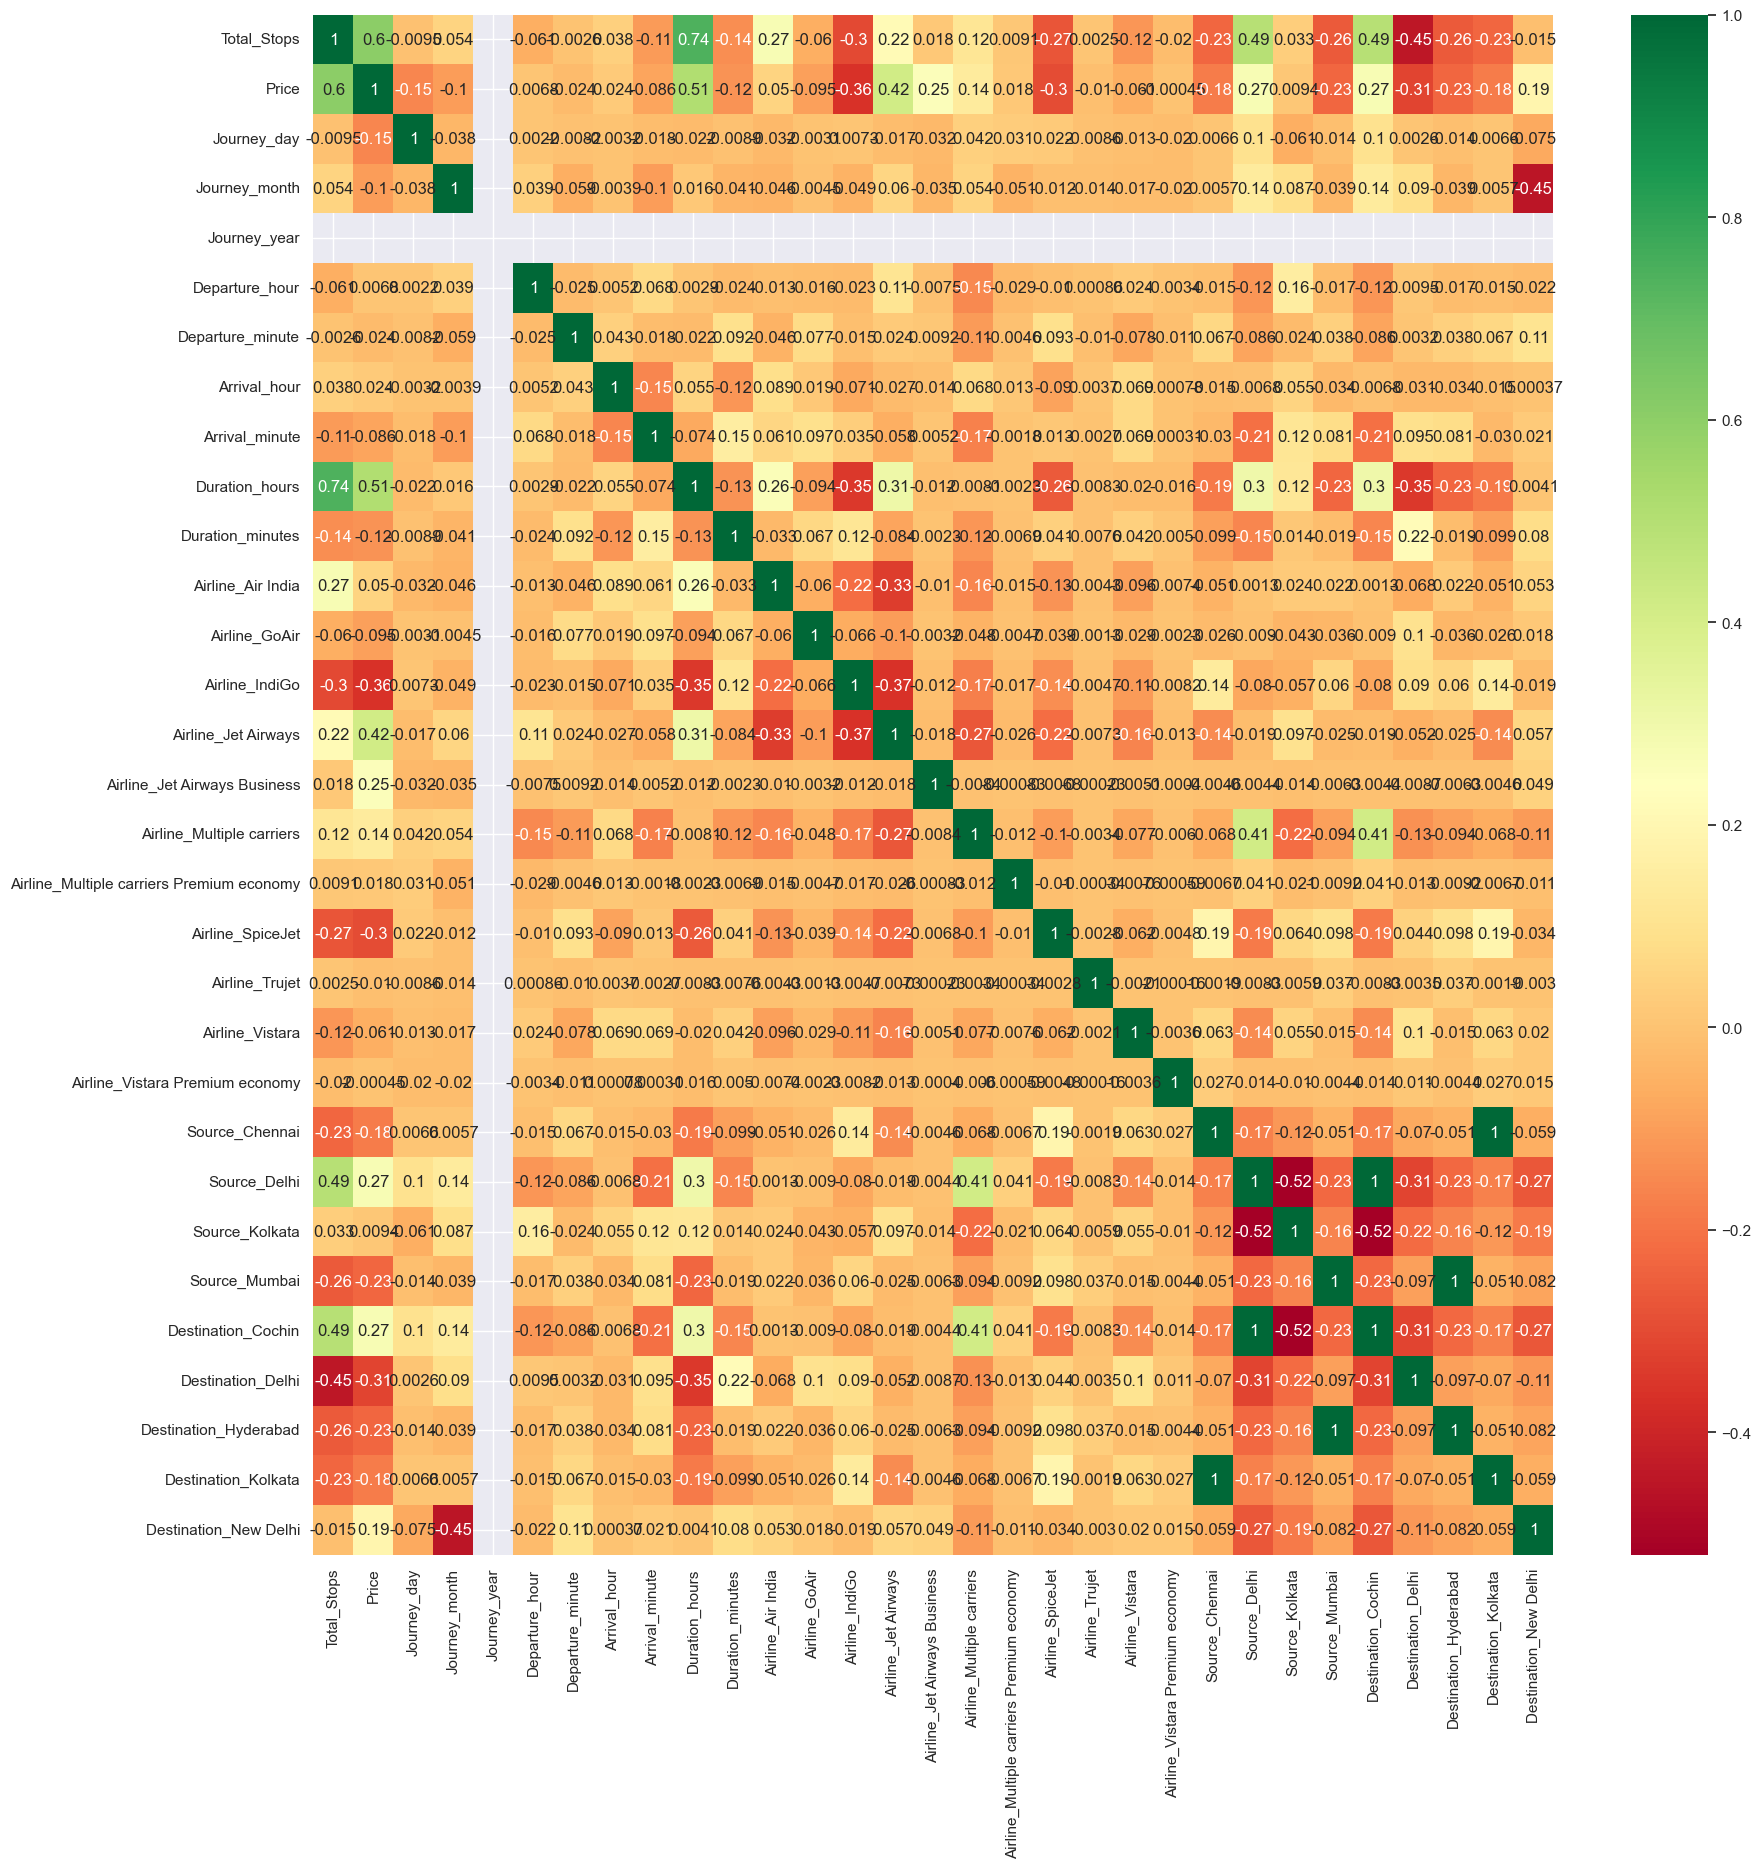

In [171]:
plt.figure(figsize=(20, 20))
sns.heatmap(train_df.corr(), annot=True, cmap='RdYlGn')

plt.show()

In [172]:
from sklearn.ensemble import ExtraTreesRegressor
selection = ExtraTreesRegressor()
selection.fit(X, y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the 

In [173]:
print(selection.feature_importances_)

[2.49505385e-01 1.44127485e-01 5.27186740e-02 0.00000000e+00
 2.44856822e-02 2.13000002e-02 2.78489377e-02 1.90120413e-02
 1.06827681e-01 1.76070532e-02 9.61536977e-03 1.90841961e-03
 2.00883301e-02 1.32639683e-01 6.72908255e-02 1.87197273e-02
 8.88436931e-04 3.07849659e-03 9.15767769e-05 4.88343817e-03
 8.79051784e-05 4.93681857e-04 9.62932937e-03 3.25651799e-03
 6.50347624e-03 1.04204554e-02 1.52784321e-02 6.36695279e-03
 5.16852644e-04 2.48091529e-02]


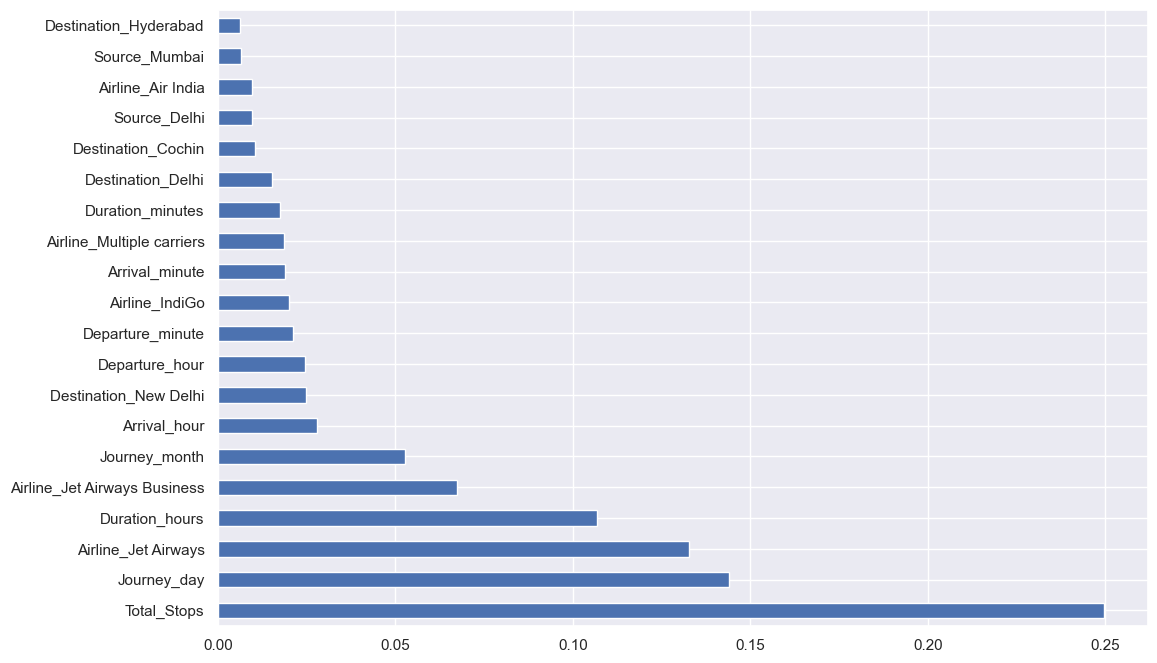

In [174]:
plt.figure(figsize=(12, 8))
feat_importance = pd.Series(selection.feature_importances_, index=X.columns)
feat_importance.nlargest(20).plot(kind='barh')
plt.show()

In [175]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [177]:
from sklearn.ensemble import RandomForestRegressor
reg_rf = RandomForestRegressor()
reg_rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [178]:
y_pred = reg_rf.predict(X_test)

In [179]:
reg_rf.score(X_train, y_train)

0.9524276258939899

In [180]:
reg_rf.score(X_test, y_test)

0.7980033444735146

C:\Users\Himanshu\AppData\Local\Temp\ipykernel_15928\523175245.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(y_test - y_pred)


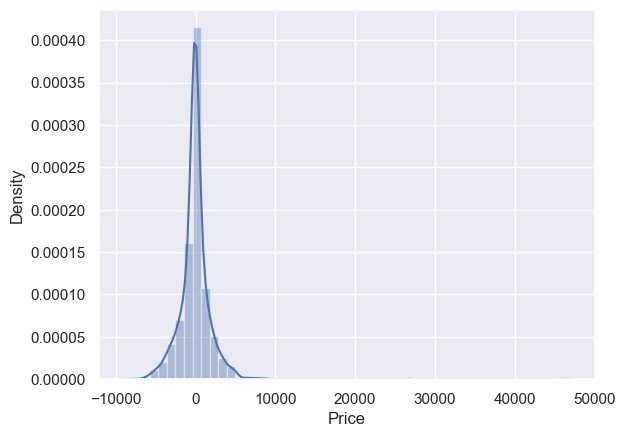

In [181]:
sns.distplot(y_test - y_pred)
plt.show()

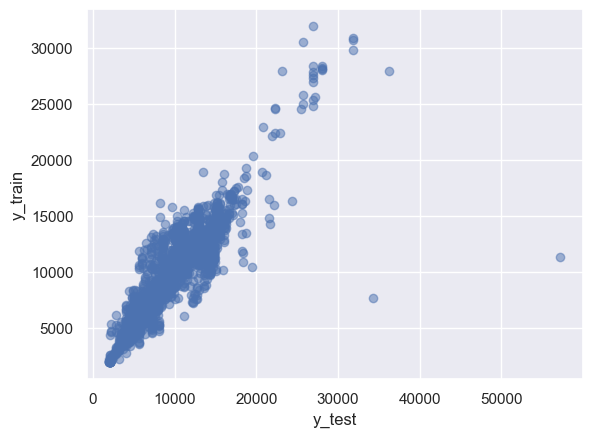

In [182]:
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel("y_test")
plt.ylabel("y_train")
plt.show()

In [183]:
from sklearn import metrics

In [184]:
print('MAE :', metrics.mean_absolute_error(y_test, y_pred))
print('MSE :', metrics.mean_squared_error(y_test, y_pred))
print('RMSE :', np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

MAE : 1168.857339038152
MSE : 4355463.263754383
RMSE : 2086.9746677318303


In [191]:
# RMSE/(max(DV)-min(DV))

print(np.sqrt(metrics.mean_squared_error(y_test, y_pred)) / (max(y)-min(y) + 0.00001))

0.026841082240729223


In [192]:
metrics.r2_score(y_test, y_pred)

0.7980033444735146

In [197]:
from sklearn.model_selection import RandomizedSearchCV

n_estimators = [int(x) for x in np.linspace(start = 100, stop = 1200, num=12)]
max_features = [None, 'sqrt']
max_depth = [int(x) for x in np.linspace(5, 30, num=6)]
min_samples_split = [2, 5, 10, 15, 100]
min_samples_leaf = [1, 2, 5, 10] 

In [198]:
random_grid = {
    'n_estimators':n_estimators,
    'max_features':max_features,
    'max_depth':max_depth,
    'min_samples_split':min_samples_split,
    'min_samples_leaf':min_samples_leaf
}

In [199]:
rf_random = RandomizedSearchCV(
    estimator=reg_rf,
    param_distributions=random_grid, 
    scoring='neg_mean_squared_error', 
    n_iter=10, 
    cv=5, 
    verbose=2, 
    random_state=42, 
    n_jobs=1
)

In [200]:
rf_random.fit(X_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=5, n_estimators=900; total time=   2.1s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=5, n_estimators=900; total time=   2.0s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=5, n_estimators=900; total time=   2.0s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=5, n_estimators=900; total time=   2.0s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=5, min_samples_split=5, n_estimators=900; total time=   2.0s
[CV] END max_depth=15, max_features=sqrt, min_samples_leaf=2, min_samples_split=10, n_estimators=1100; total time=   3.2s
[CV] END max_depth=15, max_features=sqrt, min_samples_leaf=2, min_samples_split=10, n_estimators=1100; total time=   3.5s
[CV] END max_depth=15, max_features=sqrt, min_samples_leaf=2, min_samples_split=10, n_estimator

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestRegressor()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [5, 10, ...], 'max_features': [None, 'sqrt'], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be use

In [201]:
rf_random.best_params_

{'n_estimators': 700,
 'min_samples_split': 15,
 'min_samples_leaf': 1,
 'max_features': None,
 'max_depth': 20}

In [202]:
prediction = rf_random.predict(X_test)


<Figure size 800x800 with 0 Axes>

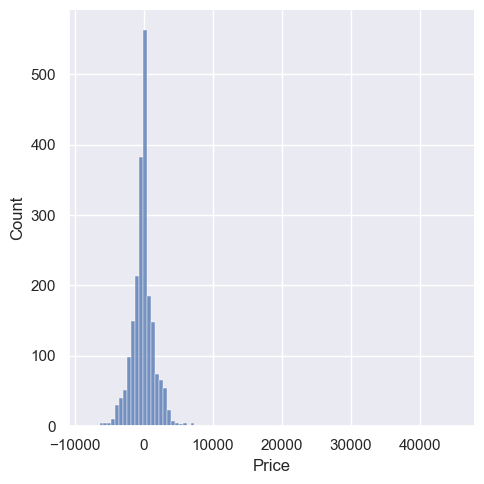

In [203]:
plt.figure(figsize=(8,8))
sns.displot(y_test - prediction)
plt.show()

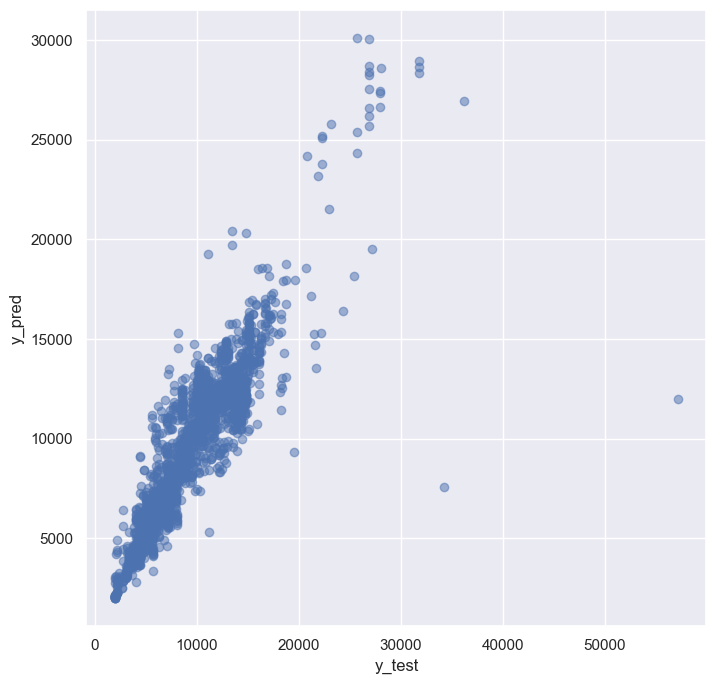

In [204]:
plt.figure(figsize=(8,8))
plt.scatter(y_test, prediction, alpha=0.5)
plt.xlabel("y_test")
plt.ylabel("y_pred")
plt.show()

In [205]:
print("MAE", metrics.mean_absolute_error(y_test, prediction))
print("MSE", metrics.mean_squared_error(y_test, prediction))
print("RMSE", np.sqrt(metrics.mean_squared_error(y_test, prediction)))

MAE 1166.1371917834995
MSE 4060176.122711496
RMSE 2014.987871604069


In [206]:
import pickle

In [207]:
file = open('flight_rf.pkl', 'wb')
pickle.dump(reg_rf, file)

In [209]:
model = open('flight_rf.pkl', 'rb')
forest = pickle.load(model)

In [210]:
y_prediction = forest.predict(X_test)
metrics.r2_score(y_test, y_prediction)

0.7980033444735146